In [ ]:
import os
import sys
from pathlib import Path

# repo root (notebooks live in notebooks/)
_root = Path.cwd()
if not (_root / "pyproject.toml").exists():
    _root = _root.parent
os.chdir(_root)
_src = _root / "src"
if _src.is_dir() and str(_src) not in sys.path:
    sys.path.insert(0, str(_src))


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import wfdb # type: ignore
import sleepecg
import neurokit2 as nk

database_name = 'mimic4wdb/0.1.0'
# database_name = 'mimic3wdb/1.0'

In [2]:
# each subject may be associated with multiple records
subjects = wfdb.get_record_list(database_name)
print(f"The '{database_name}' database contains data from {len(subjects)} subjects")

# set max number of records to load
max_records_to_load = 20

# iterate the subjects to get a list of records
records = []
for subject in subjects:
	studies = wfdb.get_record_list(f'{database_name}/{subject}')
	for study in studies:
		records.append(Path(f'{subject}{study}'))
	# stop if we've loaded enough records
	if len(records) >= max_records_to_load:
		print("Reached maximum required number of records.")
		break
        
print(f"Loaded {len(records)} records from the '{database_name}' database.")

The 'mimic4wdb/0.1.0' database contains data from 198 subjects
Reached maximum required number of records.
Loaded 20 records from the 'mimic4wdb/0.1.0' database.


In [3]:
# format and print first five records
first_five_records = [str(x).replace('\\', '/') for x in records[0:5]]
first_five_records = "\n - ".join(first_five_records)
print(f"First five records: \n - {first_five_records}")

print("""
Note the formatting of these records:
 - intermediate directory ('p100' in this case)
 - subject identifier (e.g. 'p10014354')
 - record identifier (e.g. '81739927'
 """)

First five records: 
 - waves/p100/p10014354/81739927/81739927
 - waves/p100/p10019003/87033314/87033314
 - waves/p100/p10020306/83404654/83404654
 - waves/p100/p10039708/83411188/83411188
 - waves/p100/p10039708/85583557/85583557

Note the formatting of these records:
 - intermediate directory ('p100' in this case)
 - subject identifier (e.g. 'p10014354')
 - record identifier (e.g. '81739927'
 


- Each record contains metadata stored in a header file, named "`<record name>.hea`"
- Use the [`rdheader`](https://wfdb.readthedocs.io/en/latest/io.html#wfdb.io.rdheader) function from the WFDB toolbox to load metadata from the record header file

In [4]:
# Specify the 4th record (note, in Python indexing begins at 0)
idx = 3
record = records[idx]
record_dir = f'{database_name}/{record.parent}'.replace('\\', '/')
print("PhysioNet directory specified for record: {}".format(record_dir))

record_name = record.name
print("Record name: {}".format(record_name))

# record_data = wfdb.rdheader(f'{local_base_dir}/{record.parent}/{record_name}', rd_segments=True)
record_data = wfdb.rdheader(record_name, rd_segments=True, pn_dir=record_dir)
# remote_url = "https://physionet.org/content/" + record_dir + "/" + record_name + ".hea"
print(f"Done: metadata loaded for record '{record_name}'")
display(record_data.__dict__)

print(f"- Number of signals: {record_data.n_sig}".format())
print(f"- Duration: {record_data.sig_len/(record_data.fs*60*60):.1f} hours") 
print(f"- Base sampling frequency: {record_data.fs} Hz")

segments = record_data.seg_name
print(f"The {len(segments)} segments from record {record_name} are:\n{segments}")

PhysioNet directory specified for record: mimic4wdb/0.1.0/waves/p100/p10039708/83411188
Record name: 83411188
Done: metadata loaded for record '83411188'


{'record_name': '83411188',
 'n_sig': 6,
 'fs': 62.4725,
 'counter_freq': 999.56,
 'base_counter': None,
 'sig_len': 3182400,
 'base_time': datetime.time(21, 9, 38, 555000),
 'base_date': datetime.date(2143, 9, 19),
 'comments': ['wfdb 10.7', 'subject_id 10039708', 'hadm_id 24928679'],
 'sig_name': ['II', 'V', 'aVR', 'ABP', 'Pleth', 'Resp'],
 'layout': 'variable',
 'segments': [<wfdb.io.record.Record at 0x236ffce5910>,
 'seg_name': ['83411188_0000',
  '83411188_0001',
  '83411188_0002',
  '83411188_0003',
  '83411188_0004',
  '83411188_0005'],
 'seg_len': [0, 320, 3520, 1280, 1280, 3176000],
 'sig_segments': {'II': [0, 1, 2, 3, 4, 5],
  'V': [0, 2, 3, 4, 5],
  'aVR': [0, 2, 3, 4, 5],
  'ABP': [0, 1, 2],
  'Pleth': [0, 1, 2, 3, 5],
  'Resp': [0, 1, 2, 3, 4, 5]},
 'n_seg': 6}

- Number of signals: 6
- Duration: 14.2 hours
- Base sampling frequency: 62.4725 Hz
The 6 segments from record 83411188 are:
['83411188_0000', '83411188_0001', '83411188_0002', '83411188_0003', '83411188_0004', '83411188_0005']


The format of filename for each segment is: `record directory, "_", segment number`

Header metadata loaded for: 
- the segment '83411188_0005'
- in record '83411188'
- for subject 'p10039708'

This segment contains the following signals: ['II', 'V', 'aVR', 'Pleth', 'Resp']
The signals are measured in units of: ['mV', 'mV', 'mV', 'NU', 'Ohm']
The signals have a base sampling frequency of 62.5 Hz
and they last for 847.3 minutes
Extracted the PPG signal from column 3 of the matrix of waveform data.


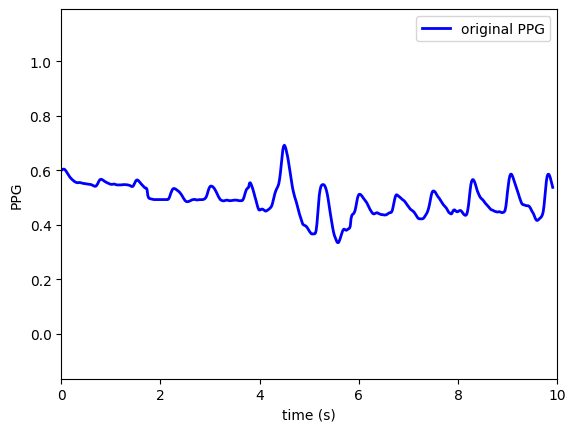

In [5]:
selected_seg_num = 5
segment_metadata = wfdb.rdheader(record_name=f'{segments[selected_seg_num]}', pn_dir=record_dir)

print(f"""Header metadata loaded for: 
- the segment '{segments[selected_seg_num]}'
- in record '{record_name}'
- for subject '{str(Path(record_dir).parent.parts[-1])}'
""")

print(f"This segment contains the following signals: {segment_metadata.sig_name}")
print(f"The signals are measured in units of: {segment_metadata.units}")
print(f"The signals have a base sampling frequency of {segment_metadata.fs:.1f} Hz")
print(f"and they last for {segment_metadata.sig_len/(segment_metadata.fs*60):.1f} minutes")

# time since the start of the segment at which to begin extracting data
start_seconds = 10
n_seconds_to_load = 10

fs = round(segment_metadata.fs)
sampfrom = fs*start_seconds
sampto = fs*(start_seconds + n_seconds_to_load)

segment_data = wfdb.rdrecord(record_name=f'{segments[selected_seg_num]}',
                             sampfrom=sampfrom,
                             sampto=sampto,
                             pn_dir=record_dir)

for sig_no in range(0, len(segment_data.sig_name)):
    if "Pleth" in segment_data.sig_name[sig_no]:
        break

ppg = segment_data.p_signal[:,sig_no]
fs = segment_data.fs
print(f"Extracted the PPG signal from column {sig_no} of the matrix of waveform data.")

fig, ax = plt.subplots()
t = np.arange(0, len(ppg))/segment_data.fs

ax.plot(t, ppg,
        linewidth=2.0,
        color = 'blue',
        label = "original PPG")

ax.set(xlim=(0, n_seconds_to_load))
plt.xlabel('time (s)')
plt.ylabel('PPG')
# plt.xlim([20, 22])
plt.ylim([min(ppg)-0.5, max(ppg)+0.5])

plt.legend()
plt.show()

See [here](https://archive.physionet.org/mimic2/mimic2_waveform_overview.shtml#signals-125-samplessecond) for definitions of signal abbreviations.

All signals in a segment are time-aligned, measured at the same sampling frequency, and last the same duration:

In [6]:
# required_sigs = ['II', 'ABP', 'Pleth']
# req_seg_duration = 5 # seconds
# matching_recs = {'subject_id':[], 'seg_name':[], 'path':[] ,'length':[]}

# for record in records:
#     print('Record: {}'.format(record), end="", flush=True)
#     record_dir = f'{database_name}/{record.parent}'.replace('\\', '/')
#     record_name = record.name
#     print(' (reading data)')
#     record_data = wfdb.rdheader(record_name=f'{record_name}',
#                                 pn_dir=record_dir,
#                                 rd_segments=True
#                                 )

#     # Check whether the required signals are present in the record
#     sigs_present = record_data.sig_name
#     if not all(x in sigs_present for x in required_sigs):
#         print('   (missing signals)')
#         continue

#     # Get the segments for the record
#     segments = record_data.seg_name

#     gen = (segment for segment in segments if segment != '~')
#     for segment in gen:
#         print(' - Segment: {}'.format(segment), end="", flush=True)
#         try:
#             segment_metadata = wfdb.rdheader(record_name=f'{segment}',
#                                              pn_dir=record_dir
#                                             )
#         except:
#             print('   (error)')
#             continue
#         seg_length = segment_metadata.sig_len/(segment_metadata.fs)

#         if seg_length < req_seg_duration:
#             print(f' (too short at {seg_length/60:.1f} mins)')
#             continue

#         sigs_present = segment_metadata.sig_name
        
#         if all(x in sigs_present for x in required_sigs):
#             # matching_recs['dir'].append(record_dir)
#             matching_recs['subject_id'].append(record_name)
#             matching_recs['seg_name'].append(segment)
#             matching_recs['path'].append(f'{record.parent}/{segment}')
#             matching_recs['length'].append(seg_length)
#             print(' (met requirements)')
#             # Since we only need one segment per record break out of loop
#             # break
#         else:
#             print(' (long enough, but missing signal(s))')

# print(f"A total of {len(matching_recs['path'])} records met the requirements:")

# df_matching_recs = pd.DataFrame(data=matching_recs)
# df_matching_recs.to_csv('model/matching_records_mimic4.csv', index=False)

Record: waves\p100\p10014354\81739927\81739927 (reading data)
   (missing signals)
Record: waves\p100\p10019003\87033314\87033314 (reading data)
   (missing signals)
Record: waves\p100\p10020306\83404654\83404654 (reading data)
 - Segment: 83404654_0000 (too short at 0.0 mins)
 - Segment: 83404654_0001 (long enough, but missing signal(s))
 - Segment: 83404654_0002 (long enough, but missing signal(s))
 - Segment: 83404654_0003 (long enough, but missing signal(s))
 - Segment: 83404654_0004 (long enough, but missing signal(s))
 - Segment: 83404654_0005 (met requirements)
 - Segment: 83404654_0006 (met requirements)
 - Segment: 83404654_0007 (long enough, but missing signal(s))
 - Segment: 83404654_0008 (met requirements)
 - Segment: 83404654_0009 (met requirements)
 - Segment: 83404654_0010 (long enough, but missing signal(s))
 - Segment: 83404654_0011 (met requirements)
 - Segment: 83404654_0012 (met requirements)
 - Segment: 83404654_0013 (met requirements)
 - Segment: 83404654_0014 (lo

KeyboardInterrupt: 

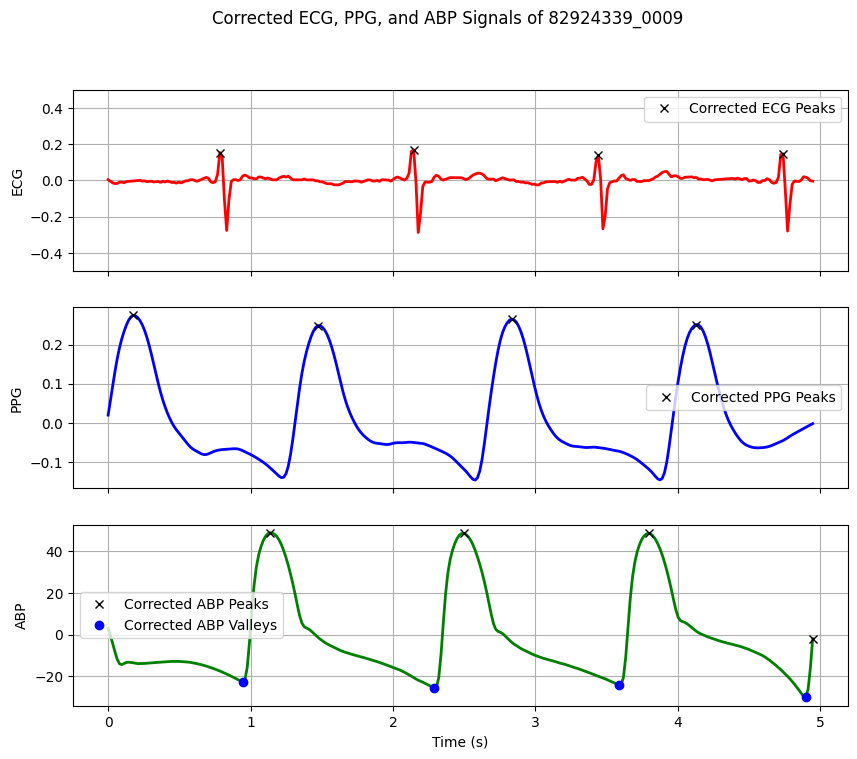

In [9]:
example_seg = Path(pd.read_csv('data/matching_records_mimic4.csv')['path'][19])
segment_metadata = wfdb.rdheader(example_seg.name, pn_dir=f'{database_name}/{example_seg.parent}'.replace('\\', '/'))
start_seconds = 55
n_seconds_to_load = 5

fs = round(segment_metadata.fs)
sampfrom = fs*start_seconds
sampto = fs*(start_seconds + n_seconds_to_load)

plot_example = wfdb.rdrecord(record_name=example_seg.name,
                             sampfrom=sampfrom,
                             sampto=sampto,
                             pn_dir=f'{database_name}/{example_seg.parent}'.replace('\\', '/'))

for sig_no in range(0, len(plot_example.sig_name)):
    if "Pleth" in plot_example.sig_name[sig_no]:
        ppg_sig_no = sig_no
    if "ABP" in plot_example.sig_name[sig_no]:
        abp_sig_no = sig_no
    if "II" in plot_example.sig_name[sig_no]:
        ecg_sig_no = sig_no

fs = plot_example.fs
ppg = plot_example.p_signal[:, ppg_sig_no]
abp = plot_example.p_signal[:, abp_sig_no]
ecg = plot_example.p_signal[:, ecg_sig_no]

ecg = nk.signal_filter(ecg, fs, 0.6)
ppg = nk.signal_filter(ppg, fs, 0.7, 10)
abp = nk.signal_filter(abp, fs, 0.5, 20)

ecg_peak_indices = sleepecg.detect_heartbeats(ecg, fs=fs)
ppg_peak_indices = sleepecg.detect_heartbeats(ppg, fs=fs)
abp_peak_indices = sleepecg.detect_heartbeats(abp, fs=fs)
abp_valley_indices = sleepecg.detect_heartbeats(-abp, fs=fs)

t = np.arange(0, len(ppg)) / plot_example.fs

search_radius = int(0.33 * fs)

def correct_peaks(signal, peak_inds, search_radius):	
	corrected_peak_inds = []
    
	for peak in peak_inds:
		# Define the search range, ensuring it stays within the signal bounds
		start = max(peak - search_radius, 0)
		end = min(peak + search_radius, len(signal) - 1)

		# Find the index of the maximum value within the search range
		max_peak_in_range = np.argmax(signal[start:end + 1])  # +1 because of the inclusive end index
		corrected_peak_inds.append(start + max_peak_in_range)
    
	return np.array(corrected_peak_inds)

# Correct the ECG peaks
corrected_ecg_peaks = correct_peaks(ecg, ecg_peak_indices, search_radius)

# Correct the PPG peaks
corrected_ppg_peaks = correct_peaks(ppg, ppg_peak_indices, search_radius)

# Correct the ABP peaks
corrected_abp_peaks = correct_peaks(abp, abp_peak_indices, search_radius)

corrected_abp_valleys = correct_peaks(-abp, abp_valley_indices, search_radius)


# Create the plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle(f'Corrected ECG, PPG, and ABP Signals of {example_seg.name}')

# Plot ECG signal and corrected peaks
ax1.plot(t, ecg, linewidth=2.0, color='red')
ax1.plot(t[corrected_ecg_peaks], ecg[corrected_ecg_peaks], "x", label='Corrected ECG Peaks', color='black')
ax1.set_ylabel('ECG')
ax1.set_ylim([-0.5, 0.5])
ax1.grid(True)
ax1.legend()

# Plot PPG signal and corrected peaks
ax2.plot(t, ppg, linewidth=2.0, color='blue')
ax2.plot(t[corrected_ppg_peaks], ppg[corrected_ppg_peaks], "x", label='Corrected PPG Peaks', color='black')
ax2.set_ylabel('PPG')
ax2.grid(True)
ax2.legend()

# Plot ABP signal with corrected peaks and valleys
ax3.plot(t, abp, linewidth=2.0, color='green')
# Plot the corrected ABP peaks
ax3.plot(t[corrected_abp_peaks], abp[corrected_abp_peaks], "x", label='Corrected ABP Peaks', color='black')
# Plot the corrected ABP valleys
ax3.plot(t[corrected_abp_valleys], abp[corrected_abp_valleys], "o", label='Corrected ABP Valleys', color='blue')  
ax3.set_ylabel('ABP')
ax3.grid(True)
ax3.legend()

# Set shared x-axis label
plt.xlabel('Time (s)')

# Display the plot
plt.show()


In [1]:
def has_continuous_constant_values(data, threshold=5):
    count = 1  # Initialize counter
    for i in range(1, len(data)):
        if data[i] == data[i - 1]:
            count += 1
            if count > threshold:  # Check if count exceeds the threshold
                return True
        else:
            count = 1  # Reset counter if values differ
    return False

def split_segment(segment_path, split_sec=5):
	# Read the segment data
	segment = Path(segment_path)
	segment_name = segment.name
	segment_dir = f'{database_name}/{segment.parent}'.replace('\\', '/')
	segment_data = wfdb.rdrecord(record_name=segment_name, pn_dir=segment_dir)

	# Identify signal indices for Pleth (PPG), ABP, and ECG
	for sig_no in range(len(segment_data.sig_name)):
		if "Pleth" in segment_data.sig_name[sig_no]:
			ppg_sig_no = sig_no
		if "ABP" in segment_data.sig_name[sig_no]:
			abp_sig_no = sig_no
		if "II" in segment_data.sig_name[sig_no]:
			ecg_sig_no = sig_no

	# Extract signal data
	ppg = segment_data.p_signal[:, ppg_sig_no]
	abp = segment_data.p_signal[:, abp_sig_no]
	ecg = segment_data.p_signal[:, ecg_sig_no]
	fs = segment_data.fs
    
	ecg = nk.signal_fillmissing(ecg)
	ppg = nk.signal_fillmissing(ppg)
	abp = nk.signal_fillmissing(abp)

	ecg = nk.signal_filter(ecg, fs, 0.6)
	ppg = nk.signal_filter(ppg, fs, 0.7, 10)
	abp = nk.signal_filter(abp, fs, 0.5, 20)
    
	split_samples = int(fs * split_sec)
	num_segments = len(ppg) // split_samples

	valid_segments = []

	for i in range(num_segments):
		# Split each signal into 5-second segments
		start_idx = i * split_samples
		end_idx = start_idx + split_samples

		ppg_segment = ppg[start_idx:end_idx]
		abp_segment = abp[start_idx:end_idx]
		ecg_segment = ecg[start_idx:end_idx]

		# Check for NaN or flat signals in any of the segments
		if (not np.any(np.isnan(ppg_segment)) and
			not np.any(np.isnan(abp_segment)) and
			not np.any(np.isnan(ecg_segment)) and
			not has_continuous_constant_values(ppg_segment) and
			not has_continuous_constant_values(abp_segment) and
			not has_continuous_constant_values(ecg_segment)):
			# If valid, add to the list of valid segments
			valid_segments.append({
				'ECG': ecg_segment,
				'PPG': ppg_segment,
				'ABP': abp_segment
			})

	return valid_segments, fs

In [2]:
def calculate_hr(corrected_peaks, fs):
    """
    Calculate heart rate from corrected peaks.
    
    Parameters:
    corrected_peaks (array-like): Indices of the corrected peaks.
    fs (int): Sampling frequency.
    
    Returns:
    hr (float): The heart rate in beats per minute (bpm).
    """
    # Calculate time differences between corrected peaks
    peak_intervals = np.diff(corrected_peaks) / fs
    
    # Calculate heart rate (HR) in beats per minute (bpm)
    hr = 60 / np.mean(peak_intervals) if len(peak_intervals) > 0 else np.nan
    
    return hr

def calculate_peak_ratio(signal, corrected_peaks, method='min'):
	"""
	Calculate the peak-to-peak amplitude ratio using the corrected peaks.

	Parameters:
	signal (array-like): The input signal (e.g., ECG or PPG).
	corrected_peaks (array-like): Indices of the corrected peaks.

	Returns:
	peak_ratio (float): Ratio of maximum peak to the mean peak height.
	"""
	# Extract the peak amplitudes from the signal using corrected peak indices
	peak_amplitudes = signal[corrected_peaks]

	# Calculate the max and mean peak amplitude
	max_peak = np.max(peak_amplitudes) if len(peak_amplitudes) > 0 else np.nan
	if method == 'min':
		min_peak = np.min(peak_amplitudes) if len(peak_amplitudes) > 0 else np.nan
		peak_ratio = max_peak / min_peak if min_peak != 0 else np.nan
	else:
		mean_peak = np.mean(peak_amplitudes) if len(peak_amplitudes) > 0 else np.nan
		peak_ratio = max_peak / mean_peak if mean_peak != 0 else np.nan
    
	return peak_ratio

def calculate_btb_ratio(corrected_peaks, fs):
    """
    Calculate the beat-to-beat (BTB) interval ratio using corrected peaks.
    
    Parameters:
    corrected_peaks (array-like): Indices of the corrected peaks.
    fs (int): Sampling frequency.
    
    Returns:
    btb_ratio (float): Ratio of the maximum to the mean beat-to-beat intervals.
    """
    # Calculate the beat-to-beat intervals from the corrected peaks
    btb_intervals = np.diff(corrected_peaks) / fs
    
    # Calculate the max and mean beat-to-beat intervals
    max_btb = np.max(btb_intervals) if len(btb_intervals) > 0 else np.nan
    min_btb = np.mean(btb_intervals) if len(btb_intervals) > 0 else np.nan
    
    btb_ratio = max_btb / min_btb if min_btb != 0 else np.nan
    
    return btb_ratio

def calculate_pulse_pressure(abp_signal, corrected_peaks, corrected_valleys):
    """
    Calculate pulse pressure using corrected ABP peaks and valleys.
    
    Parameters:
    abp_signal (array-like): The arterial blood pressure signal (ABP).
    corrected_peaks (array-like): Indices of the corrected ABP peaks.
    corrected_valleys (array-like): Indices of the corrected ABP valleys.
    
    Returns:
    pulse_pressure (float): Pulse pressure, calculated as the difference between systolic and diastolic pressures.
    """
    # Extract systolic (peak) and diastolic (valley) pressures
    systolic_pressure = np.mean(abp_signal[corrected_peaks]) if len(corrected_peaks) > 0 else np.nan
    diastolic_pressure = np.mean(abp_signal[corrected_valleys]) if len(corrected_valleys) > 0 else np.nan
    
    pulse_pressure = systolic_pressure - diastolic_pressure if np.isfinite(systolic_pressure) and np.isfinite(diastolic_pressure) else np.nan
    
    return pulse_pressure, systolic_pressure, diastolic_pressure


In [3]:
def correct_peaks(signal, peak_inds, search_radius):	
	corrected_peak_inds = []
    
	for peak in peak_inds:
		# Define the search range, ensuring it stays within the signal bounds
		start = max(peak - search_radius, 0)
		end = min(peak + search_radius, len(signal) - 1)

		# Find the index of the maximum value within the search range
		max_peak_in_range = np.argmax(signal[start:end + 1])  # +1 because of the inclusive end index
		corrected_peak_inds.append(start + max_peak_in_range)
    
	return np.array(corrected_peak_inds)

def signal_selection_algorithm(groups, fs):
	"""
	Input: groups: List of dictionaries with 'ECG', 'PPG', 'ABP' signals from split_segment function
			fs: Sampling frequency
	Output: List of valid records (those with record_quality = 1)
	"""
	valid_records = []
    
	for group in groups:
		ecg = group['ECG']
		ppg = group['PPG']
		abp = group['ABP']
        
		ecg_peak_indices = sleepecg.detect_heartbeats(ecg, fs=fs)
		ppg_peak_indices = sleepecg.detect_heartbeats(ppg, fs=fs)
		abp_peak_indices = sleepecg.detect_heartbeats(abp, fs=fs)
		abp_valley_indices = sleepecg.detect_heartbeats(-abp, fs=fs)
		
		search_radius = int(0.33 * fs)
		corrected_ecg_peaks = correct_peaks(ecg, ecg_peak_indices, search_radius)
		corrected_ppg_peaks = correct_peaks(ppg, ppg_peak_indices, search_radius)
		corrected_abp_peaks = correct_peaks(abp, abp_peak_indices, search_radius)
		corrected_abp_valleys = correct_peaks(-abp, abp_valley_indices, search_radius)
        
        # Calculate heart rates from corrected ECG and PPG peaks
		hr_ecg = calculate_hr(corrected_ecg_peaks, fs)
		hr_ppg = calculate_hr(corrected_ppg_peaks, fs)

		# Calculate peak and BTB ratios from corrected peaks
		ppg_peak_ratio = calculate_peak_ratio(ppg, corrected_ppg_peaks)
		ecg_peak_ratio = calculate_peak_ratio(ecg, corrected_ecg_peaks, method='mean')
		ppg_btb_ratio = calculate_btb_ratio(corrected_ppg_peaks, fs)
		ecg_btb_ratio = calculate_btb_ratio(corrected_ecg_peaks, fs)

		# Calculate pulse pressure from ABP signal, corrected peaks, and valleys
		pulse_pressure, true_sbp, true_dbp = calculate_pulse_pressure(abp, corrected_abp_peaks, corrected_abp_valleys)

		# Apply selection criteria from Algorithm 1
		if (
			abs(hr_ppg - hr_ecg) <= 5
			and 40 < hr_ppg < 180 
			and ppg_peak_ratio < 1.5 
			and ecg_peak_ratio < 1.5 
			and ppg_btb_ratio < 1.5 
			and ecg_btb_ratio < 1.5 
			and 20 < pulse_pressure < 60
		):
			group['true_sbp'] = true_sbp
			group['true_dbp'] = true_dbp
			valid_records.append(group)  # Valid record
            
	return valid_records

In [11]:
# valid_segments, fs = split_segment(example_seg)
# print(f'The amount of remaining segment groups after splitting: {len(valid_segments)}')
# valid_records = signal_selection_algorithm(valid_segments, fs)
# print(f'The amount of final remaining segment groups after SQI: {len(valid_records)}')

In [6]:
# Read the CSV file
# df = pd.read_csv('data/matching_records_mimic4.csv')
chunk_size = 1000
count = 0
final_records = []

for chunk in pd.read_csv('data/matching_records_mimic4.csv', chunksize=chunk_size):
	for index, row in chunk.iterrows():
		try:
			print(f'For {row["seg_name"]}')
			valid_segments, fs = split_segment(f'{row["path"]}')
			print(f'- The amount of remaining segment groups after splitting: {len(valid_segments)}')
			valid_records = signal_selection_algorithm(valid_segments, fs)
			print(f'- The amount of final remaining segment groups after SQI: {len(valid_records)}')
			count += len(valid_records)

			for r in range(len(valid_records)):
				final_records.append({
					'seg_name': f"{row['seg_name']}_{str(r)}",
					'ecg': valid_records[r]['ECG'],
					'ppg': valid_records[r]['PPG'],
					'true_sbp': valid_records[r]['true_sbp'],
					'true_dbp': valid_records[r]['true_dbp']
				})
		except:
			print('error')
			continue

np.save('data/final_records_mimic4.npy', final_records)
print(count)

For 83404654_0005
- The amount of remaining segment groups after splitting: 629


C:\Users\user\AppData\Local\Temp\ipykernel_32604\3190688756.py:16: RuntimeWarning: divide by zero encountered in scalar divide
  hr = 60 / np.mean(peak_intervals) if len(peak_intervals) > 0 else np.nan


- The amount of final remaining segment groups after SQI: 0
For 83404654_0006
- The amount of remaining segment groups after splitting: 246
- The amount of final remaining segment groups after SQI: 0
For 83404654_0008
- The amount of remaining segment groups after splitting: 2
- The amount of final remaining segment groups after SQI: 0
For 83404654_0009
- The amount of remaining segment groups after splitting: 2449
- The amount of final remaining segment groups after SQI: 4
For 83404654_0011
- The amount of remaining segment groups after splitting: 12859
- The amount of final remaining segment groups after SQI: 3
For 83404654_0012
- The amount of remaining segment groups after splitting: 17
- The amount of final remaining segment groups after SQI: 0
For 83404654_0013
- The amount of remaining segment groups after splitting: 1422
- The amount of final remaining segment groups after SQI: 1
For 83404654_0015
- The amount of remaining segment groups after splitting: 1
- The amount of final

In [1]:
import numpy as np 

final_records = np.load('data/final_records_mimic4.npy', allow_pickle=True)

for record in final_records:
    seg_name = record['seg_name']
    subject_id = seg_name.split('_')[0]  # Assuming subject_id is the first part before '_'
    record['subject_id'] = subject_id

# Convert back to numpy array if needed
final_records_with_subject_id = np.array(final_records)

# Optionally save it back to a .npy file
np.save('data/final_records_mimic4_with_id.npy', final_records_with_subject_id)